# Genotype Counts and Allele Frequencies

Estimate alternate-allele frequency from diploid genotype calls with missing observations.

Each called diploid genotype contributes two alleles. A heterozygous genotype contributes one alternate allele and a homozygous alternate genotype contributes two. Sites with zero calls have undefined frequency.

In [1]:
from pathlib import Path
import sys

here = Path.cwd()
sys.path.insert(0, str(here.parent))
import numpy as np
import matplotlib.pyplot as plt

from genome_methods import bars

## Worked example

Run the example from top to bottom. The printed check and figure use the same observations.

Site 1: AC 4, AN 8, AF 0.500
Site 2: AC 1, AN 10, AF 0.100
Site 3: AC 7, AN 8, AF 0.875
Site 4: AC 0, AN 0, AF nan


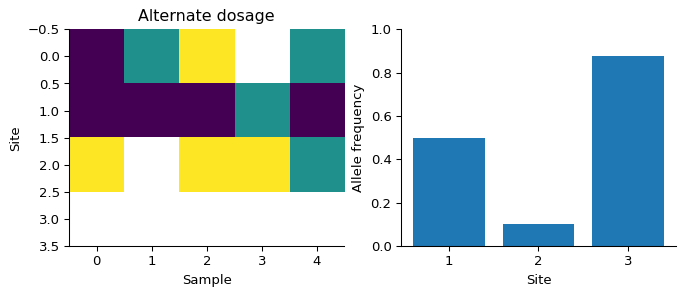

In [2]:
G = np.array([[0, 1, 2, np.nan, 1], [0, 0, 0, 1, 0], [2, np.nan, 2, 2, 1], [np.nan] * 5])
called = np.isfinite(G).sum(1)
ac = np.nansum(G, axis=1)
af = np.divide(ac, 2 * called, out=np.full(4, np.nan), where=called > 0)
for i in range(len(G)):
    print(f"Site {i+1}: AC {ac[i]:.0f}, AN {2*called[i]}, AF {af[i]:.3f}")
assert af[0] == 0.5 and np.isnan(af[-1])
fig, (a, b) = plt.subplots(1, 2, figsize=(7.1, 3), constrained_layout=True)
a.imshow(np.ma.masked_invalid(G), vmin=0, vmax=2, cmap="viridis", aspect="auto")
a.set(xlabel="Sample", ylabel="Site", title="Alternate dosage")
b.bar(range(1, 5), af)
b.set(xlabel="Site", ylabel="Allele frequency", ylim=(0, 1))
plt.show()

## Interpreting the result

A missing call supplies no allele count. Treating missing observations as reference would bias the denominator and the frequency.

## Exercise

Replace one heterozygote with a missing call and predict the new frequency before rerunning.

## References

[GA4GH VCF specification](https://samtools.github.io/hts-specs/)